# Modèle A — Comptage des WARN (baseline)

Ce notebook implémente le modèle de référence du projet sur HDFS_v1.

Règle de décision : le score d'un bloc est son nombre de messages `WARN` (`n_warn`) et une alerte est levée si `n_warn > 0`. Il n'y a aucun entraînement, aucune transformation appris et aucune machine learning. La graine 42 est fixée par cohérence avec les règles communes, même si ce modèle n'est pas aléatoire.

Le découpage fourni par `parties()` est utilisé tel quel. La partie `test` ne sert qu'à produire le fichier de prédictions final ; sa notation est faite une seule fois par `evaluate.py`, hors de ce notebook.

## 1. Imports et reproductibilité

In [1]:
import json
import os
import platform
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("../..").resolve()))
from donnees import charger_compteurs, parties, seuil, ecrire_predictions, COLONNES_E, GRAINE

np.random.seed(GRAINE)
MACHINE = os.environ.get("PROCESSOR_IDENTIFIER") or platform.platform()
SORTIE = Path("../../results/comptage_warn_test.csv")
print("graine :", GRAINE)
print("machine :", MACHINE)

graine : 42
machine : Intel64 Family 6 Model 142 Stepping 10, GenuineIntel


## 2. Chargement du jeu de données commun

`charger_compteurs()` lit `counts.parquet`, puis `parties()` applique le découpage officiel sans le recréer.

In [2]:
df = charger_compteurs()
p = parties(df)

print("dimensions :", df.shape)
print("colonnes :", list(df.columns))
tableau_split = df.groupby("split")["label"].agg(
    blocs="size", anomalies="sum", normaux=lambda s: int((s == 0).sum()), taux_anomalie="mean"
)
display(tableau_split)
print("tailles des parties :", {nom: len(partie) for nom, partie in p.items()})

dimensions : (575061, 38)
colonnes : ['block_id', 'label', 'split', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27', 'E28', 'E29', 'E30', 'n_warn', 'n_error', 'length', 'n_unique', 'duration_s']


,blocs,anomalies,normaux,taux_anomalie
split,,,,
test,86260,1116,85144,0.012938
train,402542,13115,389427,0.032580
val,86259,2607,83652,0.030223


tailles des parties : {'train': 402542, 'train_normal': 389427, 'val': 86259, 'val_normal': 83652, 'test': 86260}


## 3. Comprendre la variable `n_warn`

On regarde la répartition de `n_warn` par partie et par étiquette. Cette exploration n'utilise les étiquettes que pour comprendre le signal du baseline ; elle ne modifie ni le modèle ni son seuil, qui reste fixé à 0 par la règle du projet.

In [3]:
exploration = df.assign(avec_warn=(df["n_warn"] > 0).astype(int)).groupby(["split", "label"]).agg(
    blocs=("block_id", "size"),
    blocs_avec_warn=("avec_warn", "sum"),
    n_warn_moyen=("n_warn", "mean"),
    n_warn_max=("n_warn", "max"),
)
display(exploration)
print("valeurs nulles :", int(df["n_warn"].isna().sum()))
print("valeurs négatives :", int((df["n_warn"] < 0).sum()))
print("maximum :", int(df["n_warn"].max()))

blocs  blocs_avec_warn  n_warn_moyen  n_warn_max
split label                                                   
test  0       85144                0      0.000000           0
      1        1116              201      0.182796           2
train 0      389427           126120      0.894065          41
      1       13115             6459      0.980175          17
val   0       83652                0      0.000000           0
      1        2607             1460      0.598773           3

valeurs nulles : 0
valeurs négatives : 0
maximum : 41


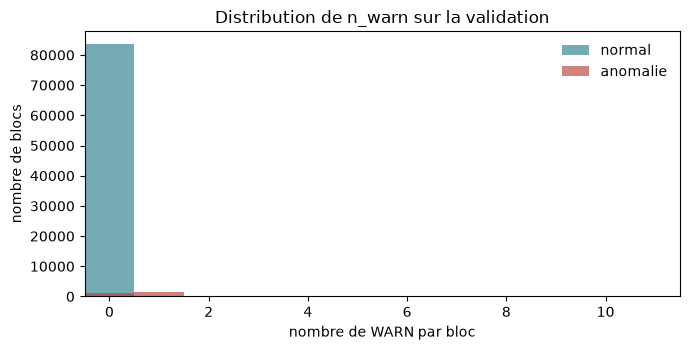

In [4]:
val = p["val"]
fig, ax = plt.subplots(figsize=(7, 3.6))
for libelle, etiquette, couleur in [("normal", 0, "#2A7F8E"), ("anomalie", 1, "#B9403A")]:
    valeurs = val.loc[val["label"] == etiquette, "n_warn"].to_numpy()
    ax.hist(valeurs, bins=np.arange(-0.5, 12.5, 1), alpha=0.65, color=couleur, label=libelle)
ax.set_title("Distribution de n_warn sur la validation")
ax.set_xlabel("nombre de WARN par bloc")
ax.set_ylabel("nombre de blocs")
ax.set_xlim(-0.5, 11.5)
ax.legend(frameon=False)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/n_warn_val.png", dpi=150)
plt.show()

### Lecture

Dans les parties `val` et `test`, tous les blocs normaux ont `n_warn = 0` : aucun faux positif n'est possible avec la règle `n_warn > 0`. En revanche, seuls les blocs anormaux qui contiennent au moins un WARN sont détectés. Le baseline devrait donc être très précis mais avoir un rappel limité. Ce constat est une propriété du découpage fourni et n'appelle aucun réglage.

## 4. Scoring et prédictions

`score = n_warn`, `pred = 1` si `score > 0`. `ecrire_predictions()` applique exactement cette convention et produit les colonnes attendues `block_id,score,pred`.

In [5]:
debut_pred = time.perf_counter()
score_test = p["test"]["n_warn"].to_numpy(dtype=float)
predictions = ecrire_predictions(p["test"], score_test, 0, str(SORTIE))
temps_pred_s = time.perf_counter() - debut_pred

print("fichier :", SORTIE.resolve())
print("lignes écrites :", len(predictions))
print("alertes :", int(predictions["pred"].sum()))
print(f"temps de prédiction : {temps_pred_s:.6f} s")

fichier : C:\LOGsentinel\hdfs_v1\results\comptage_warn_test.csv
lignes écrites : 86260
alertes : 201
temps de prédiction : 0.238752 s


## 5. Vérification du fichier de prédictions

Contrôles effectués avant toute notation officielle : colonnes, nombre de blocs, identifiants uniques et cohérents avec `test`, correspondance exacte des scores avec `n_warn`, valores de `pred` dans `{0, 1}` et règle `pred = (score > 0)`.

In [6]:
fichier = pd.read_csv(SORTIE, dtype={"block_id": str})
verite_ids = p["test"]["block_id"].astype(str)
scores_attendus = p["test"].assign(block_id=verite_ids).set_index("block_id").loc[fichier["block_id"], "n_warn"].to_numpy()

assert list(fichier.columns) == ["block_id", "score", "pred"]
assert len(fichier) == len(p["test"])
assert not fichier["block_id"].duplicated().any()
assert set(fichier["block_id"]) == set(verite_ids)
assert np.array_equal(fichier["score"].to_numpy(), scores_attendus.astype(float))
assert set(fichier["pred"].unique()) <= {0, 1}
assert np.array_equal(fichier["pred"].to_numpy(), (fichier["score"] > 0).astype(int).to_numpy())
print("Tous les contrôles du fichier de prédictions sont passés.")
display(fichier.head())

Tous les contrôles du fichier de prédictions sont passés.


,block_id,score,pred
0,blk_3458545012440520721,0.0,0
1,blk_-1160437354072569825,0.0,0
2,blk_-8961379332018832424,0.0,0
3,blk_-7458466477853961957,0.0,0
4,blk_3070076663445833576,0.0,0


## 6. Contrôle sur la validation (jamais sur le test)

Les mesures ci-dessous sont calculées sur `val` uniquement. Elles servent de repère interne ; les chiffres officiels sont ceux de `evaluate.py`.

In [7]:
y_val = p["val"]["label"].to_numpy()
pred_val = (p["val"]["n_warn"].to_numpy() > 0).astype(int)
vp = int(((y_val == 1) & (pred_val == 1)).sum())
fp = int(((y_val == 0) & (pred_val == 1)).sum())
fn = int(((y_val == 1) & (pred_val == 0)).sum())
vn = int(((y_val == 0) & (pred_val == 0)).sum())
precision = vp / (vp + fp) if vp + fp else 0.0
rappel = vp / (vp + fn) if vp + fn else 0.0
f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0.0
mesures_val = {"precision": precision, "rappel": rappel, "f1": f1,
               "VP": vp, "FP": fp, "FN": fn, "VN": vn}
print(pd.Series(mesures_val).to_string())

precision        1.000000
rappel           0.560031
f1               0.717974
VP            1460.000000
FP               0.000000
FN            1147.000000
VN           83652.000000


## 7. Résumé

- Modèle sans entraînement : temps d'entraînement = 0 minute par définition.
- Score et prédiction directement dérivés de `n_warn`, seuil fixe 0.
- Fichier généré : `results/comptage_warn_test.csv`, vérifié avant notation.
- Le temps de prédiction mesuré est sauvegardé dans `mesures_baseline.json` pour être transmis tel quel à `evaluate.py`.

In [8]:
mesures = {
    "modele": "Comptage des WARN",
    "membre": "Mouad",
    "regle": "score = n_warn ; pred = 1 si n_warn > 0",
    "seuil": 0,
    "validation": mesures_val,
    "train_time_min": 0.0,
    "pred_time_s": round(temps_pred_s, 6),
    "machine": MACHINE,
    "fichier": SORTIE.name,
}
Path("mesures_baseline.json").write_text(
    json.dumps(mesures, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(mesures, indent=2, ensure_ascii=False))

{
  "modele": "Comptage des WARN",
  "membre": "Mouad",
  "regle": "score = n_warn ; pred = 1 si n_warn > 0",
  "seuil": 0,
  "validation": {
    "precision": 1.0,
    "rappel": 0.5600306866129651,
    "f1": 0.7179739365625769,
    "VP": 1460,
    "FP": 0,
    "FN": 1147,
    "VN": 83652
  },
  "train_time_min": 0.0,
  "pred_time_s": 0.238752,
  "machine": "Intel64 Family 6 Model 142 Stepping 10, GenuineIntel",
  "fichier": "comptage_warn_test.csv"
}
